# Collapse-Dynamik: wie schnell Dimensionen verloren gehen, wann alles kollabiert, ob es zurückkommt

**Fragen.**
1. Wie schnell gehen die Dimensionen verloren, wenn der Trustworthiness-Sollwert stufenweise sinkt?
2. Wann ist der Collapse vollständig (alle 8 Dimensionen)?
3. Kommt es zurück, wenn man danach wieder T(μ) = 0,9 ansteuert, und wie schnell?
4. **Ist Hinzufügen teurer als Wegnehmen?** Braucht derselbe Zustand (T(μ) = 0,9) auf dem Rückweg mehr Rate, mehr Zeit,
   anderes β als auf dem direkten Weg?

**Daten (kein neues Training).** Treppe `T_stair_to0.55_s*` (Sollwert 0,95 → 0,85 → 0,75 → 0,65 → 0,55, je 1.000
Epochen) und Abzweige `T_stair_b{0.75,0.65,0.55}to0.90_s*` (zurück auf 0,9, 1.000 Epochen) aus `trustworthiness_annealer`
§14, dazu die direkten 0,9-Läufe `H_T0.900_k20_e2000_s*` (§11) als Referenz. Ausgewertet werden die Controller-Logs
(jede Epoche, alle 1.001 Validierungspatienten).

**Definitionen.**
- **Tot** = Collapse nach Lucas et al. (2019): Dimension j mit P_x[KL(q(z_j|x) ‖ p(z_j)) < ε] ≥ 1 − δ, ε = 0,01 Nats,
  δ = 1 % (`PosteriorCollapseConfig`, Spalte `collapsed_dimensions`).
- **Rate** = mittlere Gesamt-KL über die Validierungspatienten (Nats). Keine MI.
- **Vollständiger Collapse** = 8 tote Dimensionen; zusätzlich `zero_patients` = Anteil der Patienten mit μ = 0 in allen
  Dimensionen.
- T(μ) wird nicht jede Epoche gemessen (Controller-Takt); Zeitangaben dazu sind auf diesen Takt genau.

Es werden nur fertige Läufe gelesen (`run.json` vorhanden); laufende Seeds kommen beim erneuten Ausführen dazu.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "beta_vae_experiments").is_dir())
EXPERIMENTS = PROJECT_ROOT / "beta_vae_experiments"
RUNS = EXPERIMENTS / "outputs" / "trustworthiness_annealer" / "runs"
OUTPUT = EXPERIMENTS / "outputs" / "collapse_dynamics"
OUTPUT.mkdir(parents=True, exist_ok=True)

STARTS = (0, 1100, 2100, 3100, 4100)  # Beginn jeder Stufe (erste Stufe inkl. 100 Epochen Warm-up)
LEVELS = (0.95, 0.85, 0.75, 0.65, 0.55)
STAIR_END = 5100
BRANCHES = (0.75, 0.65, 0.55)
RETURN_TARGET, BAND, RETURN_EPOCHS = 0.90, 0.01, 1000
LATENT_DIM = 8
SEEDS = (17, 23, 31)


def level_end(level):
    index = LEVELS.index(level)
    return STARTS[index + 1] if index + 1 < len(STARTS) else STAIR_END


def finished(name):
    return (RUNS / name / "run.json").exists()


def load(name):
    log = pd.read_csv(RUNS / name / "controller_log.csv").set_index("epoch")
    log["alive"] = LATENT_DIM - log.collapsed_dimensions
    return log


stairs = {seed: load(f"T_stair_to0.55_s{seed}") for seed in SEEDS if finished(f"T_stair_to0.55_s{seed}")}
branches = {(seed, branch): load(f"T_stair_b{branch:.2f}to0.90_s{seed}") for seed in SEEDS for branch in BRANCHES
            if finished(f"T_stair_b{branch:.2f}to0.90_s{seed}")}
direct = {seed: load(f"H_T0.900_k20_e2000_s{seed}") for seed in SEEDS if finished(f"H_T0.900_k20_e2000_s{seed}")}
seed_colors = dict(zip(SEEDS, ("#1b6ca8", "#d1495b", "#3a7d44")))
branch_colors = dict(zip(BRANCHES, ("#5b2a86", "#c8377a", "#f0a202")))
print("Treppen:", sorted(stairs), "| Abzweige:", sorted(branches), "| direkt 0,9:", sorted(direct))

Treppen: [17, 23, 31] | Abzweige: [(17, 0.55), (17, 0.65), (17, 0.75), (23, 0.65), (23, 0.75)] | direkt 0,9: [17, 23, 31]


## 1. Wie schnell gehen die Dimensionen verloren?

Pro Stufenwechsel: tote Dimensionen vorher und am Stufenende, Epochen bis zum ersten Tod, Epochen bis der Endwert
erreicht ist und bis zum Stufenende hält, wie oft der Zähler zwischendurch wieder sinkt („Flackern“ an der Grenze ε),
β/d beim ersten Tod und die Rate vorher und nachher (Median der letzten 50 bzw. 200 Epochen).

In [2]:
speed_rows = []
for seed, log in stairs.items():
    for start, level in zip(STARTS[1:], LEVELS[1:]):
        segment = log.loc[start + 1:level_end(level)]
        before, final = int(log.loc[start, "collapsed_dimensions"]), int(segment.collapsed_dimensions.iloc[-1])
        first = segment.index[segment.collapsed_dimensions > before]
        holds = (segment.collapsed_dimensions[::-1] == final).cummin()[::-1]
        speed_rows.append(dict(
            seed=seed, Stufe=level, tot_vorher=before, tot_nachher=final, verloren=final - before,
            erster_Tod_nach=int(first[0] - start) if len(first) else np.nan,
            Endwert_haelt_ab=int(segment.index[holds][0] - start) if final > before else np.nan,
            Flackern=int((segment.collapsed_dimensions.diff() < 0).sum()),
            bd_beim_ersten_Tod=log.loc[first[0], "beta_over_d"] if len(first) else np.nan,
            bd_vorher=log.loc[start - 50:start, "beta_over_d"].median(),
            Rate_vorher=log.loc[start - 50:start, "rate"].median(),
            Rate_nachher=segment.rate.iloc[-200:].median()))
speed = pd.DataFrame(speed_rows)
speed.to_csv(OUTPUT / "loss_speed.csv", index=False)
display(speed.round(4))

,seed,Stufe,tot_vorher,tot_nachher,verloren,erster_Tod_nach,Endwert_haelt_ab,Flackern,bd_beim_ersten_Tod,bd_vorher,Rate_vorher,Rate_nachher
0,17,0.85,0,1,1,76.0,76.0,0,0.0026,0.0002,14.6374,1.9410
1,17,0.75,1,5,4,23.0,338.0,4,0.0041,0.0017,1.9535,2.5129
2,17,0.65,5,6,1,53.0,61.0,1,0.0042,0.0010,2.4593,0.3016
3,17,0.55,6,8,2,14.0,15.0,0,0.0073,0.0047,0.3103,0.0002
4,23,0.85,0,0,0,NaN,NaN,0,NaN,0.0002,14.0955,1.6577
5,23,0.75,0,4,4,16.0,160.0,8,0.0039,0.0020,1.6441,0.6968
6,23,0.65,4,6,2,21.0,792.0,5,0.0067,0.0027,0.6878,0.5498
7,23,0.55,6,8,2,23.0,741.0,0,0.0054,0.0022,0.5619,0.0002
8,31,0.85,0,0,0,NaN,NaN,0,NaN,0.0001,22.6013,1.6756
9,31,0.75,0,5,5,15.0,23.0,0,0.0033,0.0021,1.6653,0.7135


**Bild 1 — die ganze Treppe.** Tote Dimensionen, β/d, Rate und gemessenes T(μ) über die Epochen, alle Seeds. Graue
Linien = Stufenwechsel, Zahlen oben = Sollwert der Stufe.

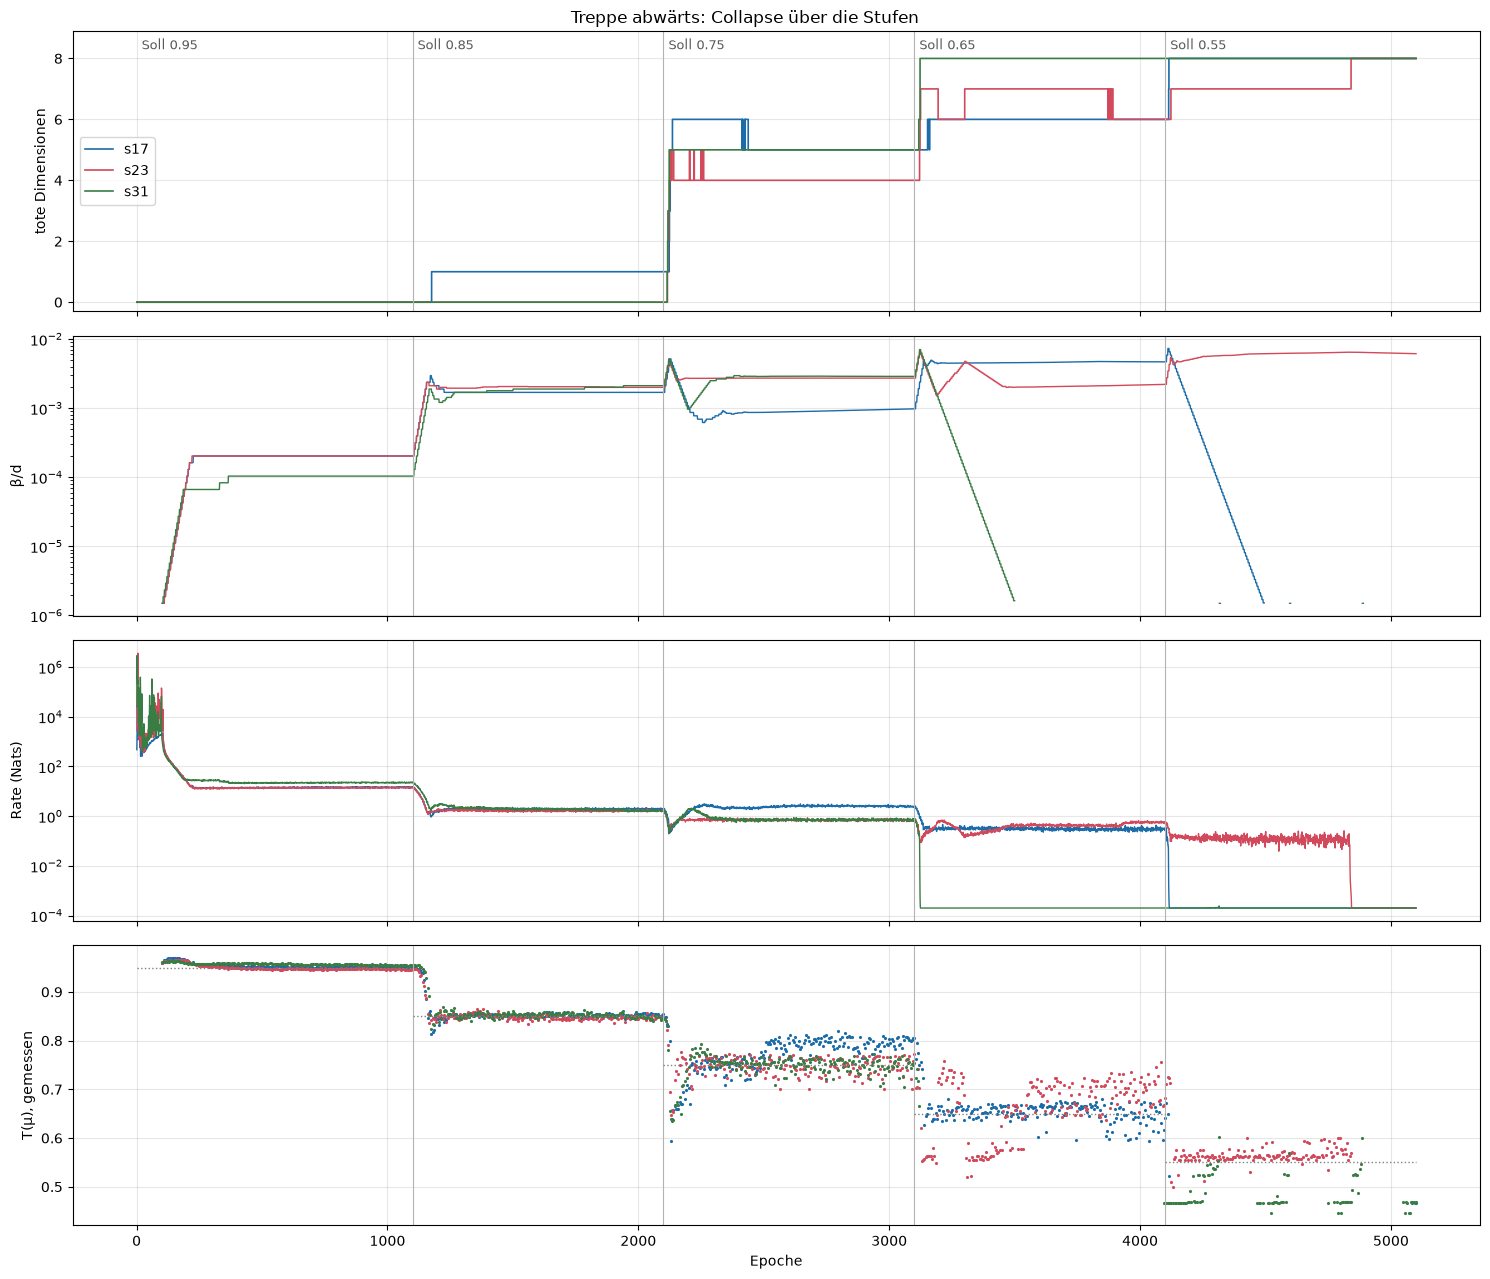

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)
for seed, log in stairs.items():
    color = seed_colors[seed]
    axes[0].step(log.index, log.collapsed_dimensions, where="post", color=color, lw=1.2, label=f"s{seed}")
    axes[1].plot(log.index, log.beta_over_d.where(log.beta_over_d > 0), color=color, lw=1)
    axes[2].plot(log.index, log.rate, color=color, lw=1)
    measured = log.metric_value.dropna()
    axes[3].plot(measured.index, measured, ".", ms=2.5, color=color)
for axis, label in zip(axes, ("tote Dimensionen", "β/d", "Rate (Nats)", "T(μ), gemessen")):
    axis.set_ylabel(label)
    for start in STARTS[1:]:
        axis.axvline(start, color="0.7", lw=.8)
    axis.grid(alpha=.3)
for start, level in zip(STARTS, LEVELS):
    axes[0].text(start + 20, 8.3, f"Soll {level}", fontsize=9, color="0.35")
    axes[3].hlines(level, start, level_end(level), color="0.5", ls=":", lw=1)
axes[1].set_yscale("log"); axes[2].set_yscale("log")
axes[0].set_ylim(-0.3, 8.9); axes[0].legend(loc="center left")
axes[3].set_xlabel("Epoche")
fig.suptitle("Treppe abwärts: Collapse über die Stufen")
fig.tight_layout()
fig.savefig(OUTPUT / "stair_overview.png", dpi=150)
plt.show()

**Bild 2 — Zoom auf jeden Stufenwechsel** (−20 bis +200 Epochen). Oben tote Dimensionen, unten β/d: Wie schnell folgt
der Tod auf den β-Anstieg des Controllers?

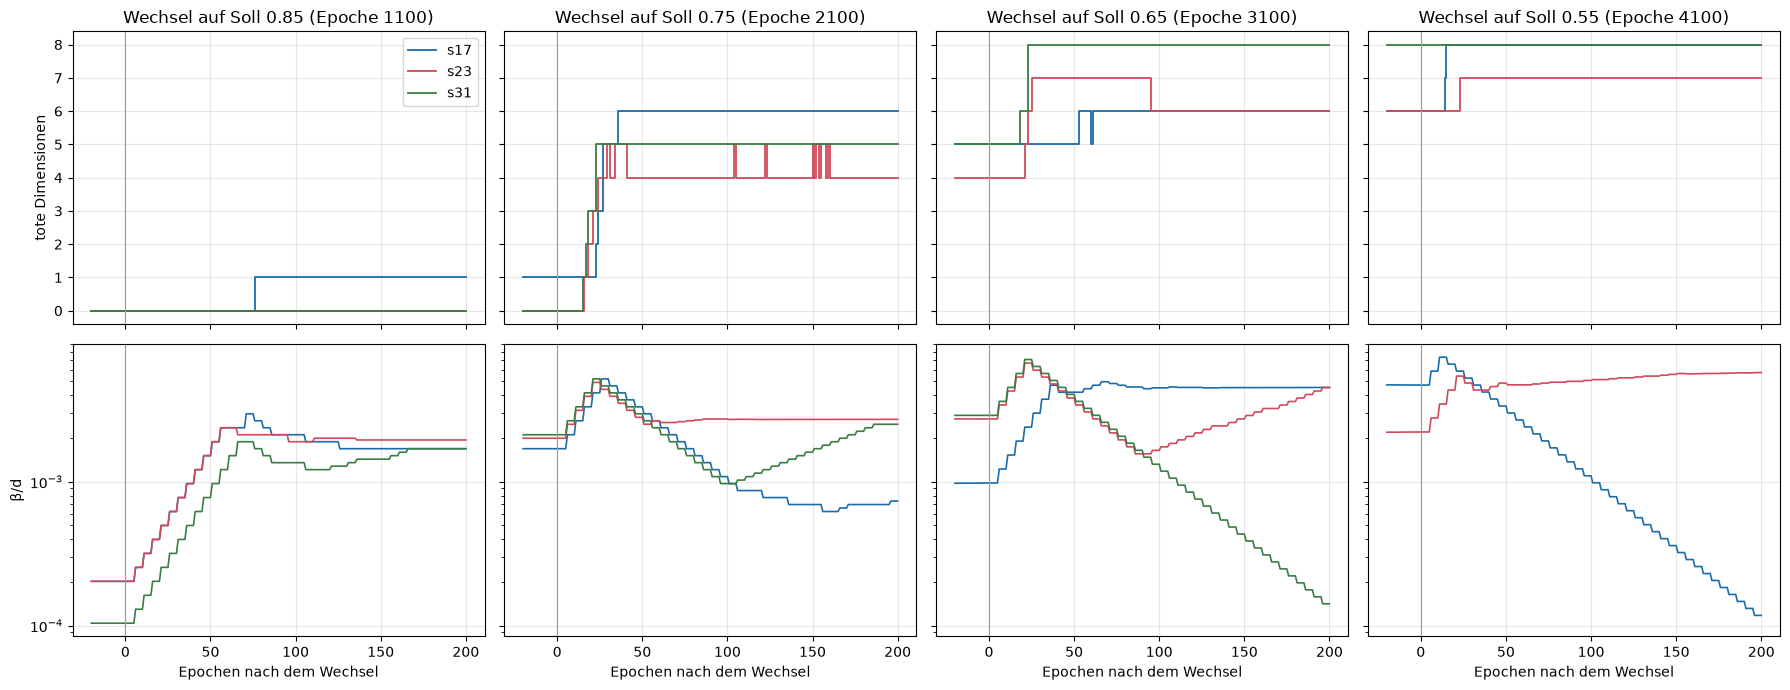

In [4]:
fig, axes = plt.subplots(2, len(STARTS) - 1, figsize=(18, 7), sharex=True, sharey="row")
for column, (start, level) in enumerate(zip(STARTS[1:], LEVELS[1:])):
    for seed, log in stairs.items():
        window = log.loc[start - 20:start + 200]
        axes[0, column].step(window.index - start, window.collapsed_dimensions, where="post",
                             color=seed_colors[seed], lw=1.3, label=f"s{seed}")
        axes[1, column].plot(window.index - start, window.beta_over_d.where(window.beta_over_d > 0),
                             color=seed_colors[seed], lw=1.2)
    axes[0, column].set_title(f"Wechsel auf Soll {level} (Epoche {start})")
    axes[1, column].set_xlabel("Epochen nach dem Wechsel")
    for axis in axes[:, column]:
        axis.axvline(0, color="0.6", lw=.8)
        axis.grid(alpha=.3)
axes[0, 0].set_ylabel("tote Dimensionen"); axes[1, 0].set_ylabel("β/d"); axes[1, 0].set_yscale("log")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(OUTPUT / "stair_transitions_zoom.png", dpi=150)
plt.show()

## 2. Wann ist der Collapse vollständig?

Erste Epoche mit 8 toten Dimensionen, die bis zum Treppenende hält, erste Epoche, in der jeder Patient μ = 0 in allen
Dimensionen hat, und β/d, Rate und Sollwert in diesem Moment.

In [5]:
total_rows = []
for seed, log in stairs.items():
    holds = (log.collapsed_dimensions[::-1] == LATENT_DIM).cummin()[::-1]
    first_total = log.index[holds][0] if holds.any() else None
    all_zero = log.index[log.zero_patients >= 1]
    total_rows.append(dict(
        seed=seed, vollstaendig_ab=first_total,
        Sollwert=next(level for start, level in zip(STARTS[::-1], LEVELS[::-1]) if first_total > start) if first_total else None,
        Epochen_nach_Stufenwechsel=first_total - max(start for start in STARTS if start < first_total) if first_total else None,
        bd_dabei=log.loc[first_total, "beta_over_d"] if first_total else None,
        bd_max_vorher=log.loc[:first_total, "beta_over_d"].max() if first_total else None,
        Rate_dabei=log.loc[first_total, "rate"] if first_total else None,
        alle_mu_null_ab=all_zero[0] if len(all_zero) else None,
        letzte_Stufe_mit_lebender_Dim=min((level for start, level in zip(STARTS, LEVELS)
                                           if log.loc[start + 1:level_end(level), "alive"].iloc[-1] > 0), default=None)))
total = pd.DataFrame(total_rows)
total.to_csv(OUTPUT / "total_collapse.csv", index=False)
display(total)

,seed,vollstaendig_ab,Sollwert,Epochen_nach_Stufenwechsel,bd_dabei,bd_max_vorher,Rate_dabei,alle_mu_null_ab,letzte_Stufe_mit_lebender_Dim
0,17,4115,0.55,15,0.007317,0.007317,0.000530,4117,0.65
1,23,4841,0.55,741,0.006471,0.006651,0.000551,4844,0.65
2,31,3123,0.65,23,0.007046,0.007046,0.000557,3125,0.75


## 3. Kommt es zurück?

Pro Abzweig (Rückkehr auf T(μ) = 0,9 nach 1.000 Epochen auf der Stufe): lebende Dimensionen beim Abzweig, am Ende und
höchstens zwischendurch, Epochen bis zur ersten T-Messung im Band 0,9 ± 0,01 und bis T stabil im Band ist (erste
Messung im Band, ab der ≥ 80 % aller folgenden Messungen im Band liegen), Epochen bis zur ersten wiederkehrenden Dimension, Endwerte von
Rate und β/d (Median der letzten 200 Epochen).

In [6]:
def stable_from(measured, band=BAND, share=0.8):
    inside = (measured - RETURN_TARGET).abs() <= band
    later_share = inside[::-1].expanding().mean()[::-1]
    ok = later_share.index[(later_share >= share) & inside]  # Beginn muss selbst im Band liegen
    return ok[0] if len(ok) else None


return_rows = []
for (seed, branch), log in branches.items():
    start = level_end(branch)
    segment = log.loc[start + 1:]
    measured = segment.metric_value.dropna()
    entered = measured.index[(measured - RETURN_TARGET).abs() <= BAND]
    stable = stable_from(measured)
    alive_at = int(log.loc[start, "alive"])
    regained = segment.index[segment.alive > alive_at]
    return_rows.append(dict(
        seed=seed, Abzweig=branch, lebend_beim_Abzweig=alive_at, lebend_am_Ende=int(segment.alive.iloc[-1]),
        lebend_max=int(segment.alive.max()),
        erste_Dim_zurueck_nach=int(regained[0] - start) if len(regained) else np.nan,
        T_im_Band_nach=int(entered[0] - start) if len(entered) else np.nan,
        T_stabil_nach=int(stable - start) if stable else np.nan,
        T_Ende=measured.iloc[-5:].median(), Rate_Ende=segment.rate.iloc[-200:].median(),
        bd_Ende=segment.beta_over_d.iloc[-200:].median(),
        alle_mu_null_beim_Abzweig=float(log.loc[start, "zero_patients"])))
returns = pd.DataFrame(return_rows).sort_values(["seed", "Abzweig"], ascending=[True, False])
returns.to_csv(OUTPUT / "comeback.csv", index=False)
display(returns.round(4))

,seed,Abzweig,lebend_beim_Abzweig,lebend_am_Ende,lebend_max,erste_Dim_zurueck_nach,T_im_Band_nach,T_stabil_nach,T_Ende,Rate_Ende,bd_Ende,alle_mu_null_beim_Abzweig
0,17,0.75,3,4,4,69.0,80.0,80.0,0.8998,9.1750,0.0003,0.2318
1,17,0.65,2,4,4,131.0,185.0,440.0,0.8997,8.4657,0.0003,0.5674
2,17,0.55,0,0,0,NaN,NaN,NaN,0.7711,0.0010,0.0000,0.9990
3,23,0.75,4,5,5,394.0,90.0,90.0,0.9010,6.7112,0.0005,0.2967
4,23,0.65,2,2,2,NaN,265.0,265.0,0.9038,3006.1750,0.0000,0.5305


**Bild 3 — die Rückwege.** Lebende Dimensionen, T(μ), Rate und β/d über die Epochen seit dem Rückschalten auf 0,9.
Farbe = Abzweig, Linienart = Seed; schwarz gestrichelt = direkter 0,9-Lauf desselben Seeds (Median der letzten 200
Epochen).

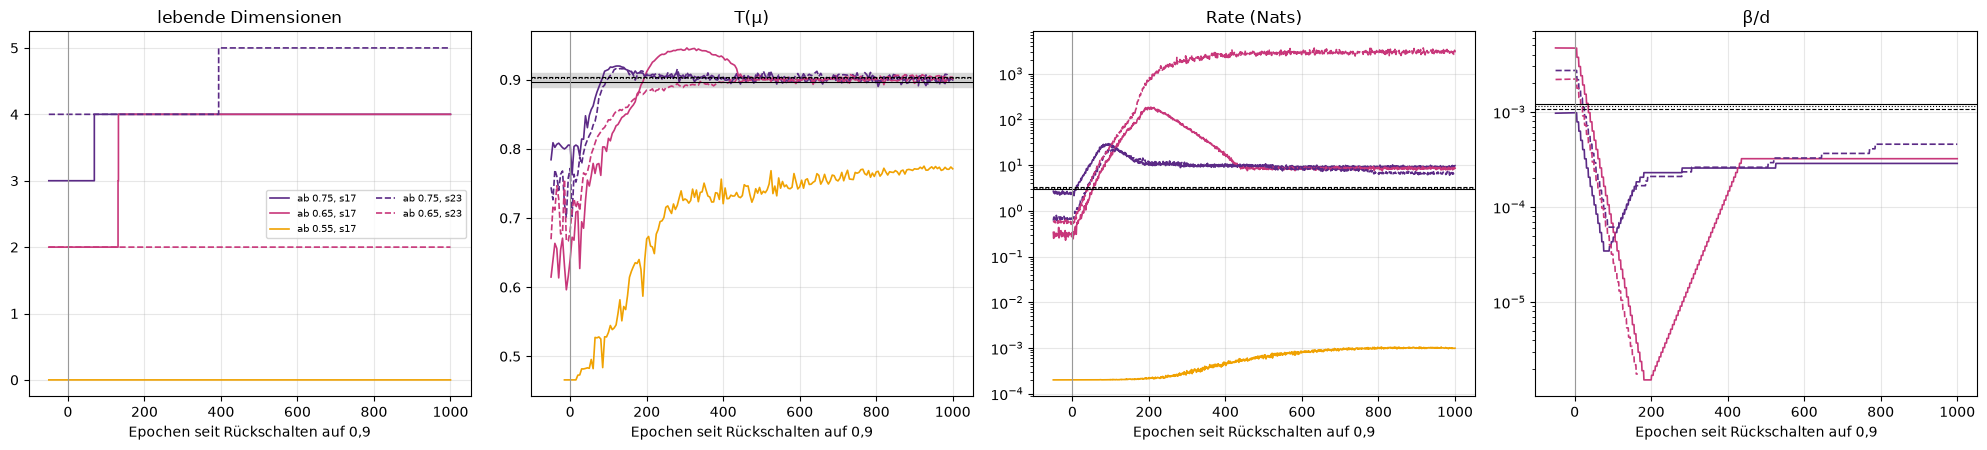

In [7]:
seed_styles = dict(zip(SEEDS, ("-", "--", ":")))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for (seed, branch), log in branches.items():
    start = level_end(branch)
    segment = log.loc[start - 50:]
    since = segment.index - start
    style = dict(color=branch_colors[branch], ls=seed_styles[seed], lw=1.2)
    axes[0].step(since, segment.alive, where="post", label=f"ab {branch}, s{seed}", **style)
    measured = segment.metric_value.dropna()
    axes[1].plot(measured.index - start, measured, **style)
    axes[2].plot(since, segment.rate, **style)
    axes[3].plot(since, segment.beta_over_d.where(segment.beta_over_d > 0), **style)
for seed, log in direct.items():
    tail = log.iloc[-200:]
    axes[1].axhline(tail.metric_value.median(), color="k", ls=seed_styles[seed], lw=.8)
    axes[2].axhline(tail.rate.median(), color="k", ls=seed_styles[seed], lw=.8)
    axes[3].axhline(tail.beta_over_d.median(), color="k", ls=seed_styles[seed], lw=.8)
for axis, title in zip(axes, ("lebende Dimensionen", "T(μ)", "Rate (Nats)", "β/d")):
    axis.set_title(title); axis.set_xlabel("Epochen seit Rückschalten auf 0,9"); axis.axvline(0, color="0.6", lw=.8)
    axis.grid(alpha=.3)
axes[1].axhspan(RETURN_TARGET - BAND, RETURN_TARGET + BAND, color="0.85", zorder=0)
axes[2].set_yscale("log"); axes[3].set_yscale("log")
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "comeback_paths.png", dpi=150)
plt.show()

## 4. Ist Hinzufügen teurer als Wegnehmen?

Drei Kosten, jeweils für denselben Zielzustand T(μ) = 0,9:
- **Rate:** Rate am Ende des Rückwegs gegen die Rate des direkten 0,9-Laufs desselben Seeds; dazu Rate pro lebender
  Dimension.
- **β:** β/d, das der Controller auf dem Rückweg für T = 0,9 hält, gegen das β/d des direkten Laufs.
- **Zeit:** Abbau (Epochen vom Stufenwechsel bis zum ersten Tod und bis der Endwert hält, §1) gegen Aufbau (Epochen vom
  Rückschalten bis zur ersten wiederkehrenden Dimension, bis T im Band und bis T stabil im Band ist, §3).

**Bild 4 — Hysterese.** Rate gegen T(μ) (nur Epochen mit T-Messung) und lebende Dimensionen gegen T(μ): Treppe abwärts
grau, Rückwege farbig, direkter 0,9-Lauf als Stern. Liegen die Rückwege bei gleichem T höher als der direkte Lauf, kostet
derselbe Zustand auf dem Rückweg mehr Rate.

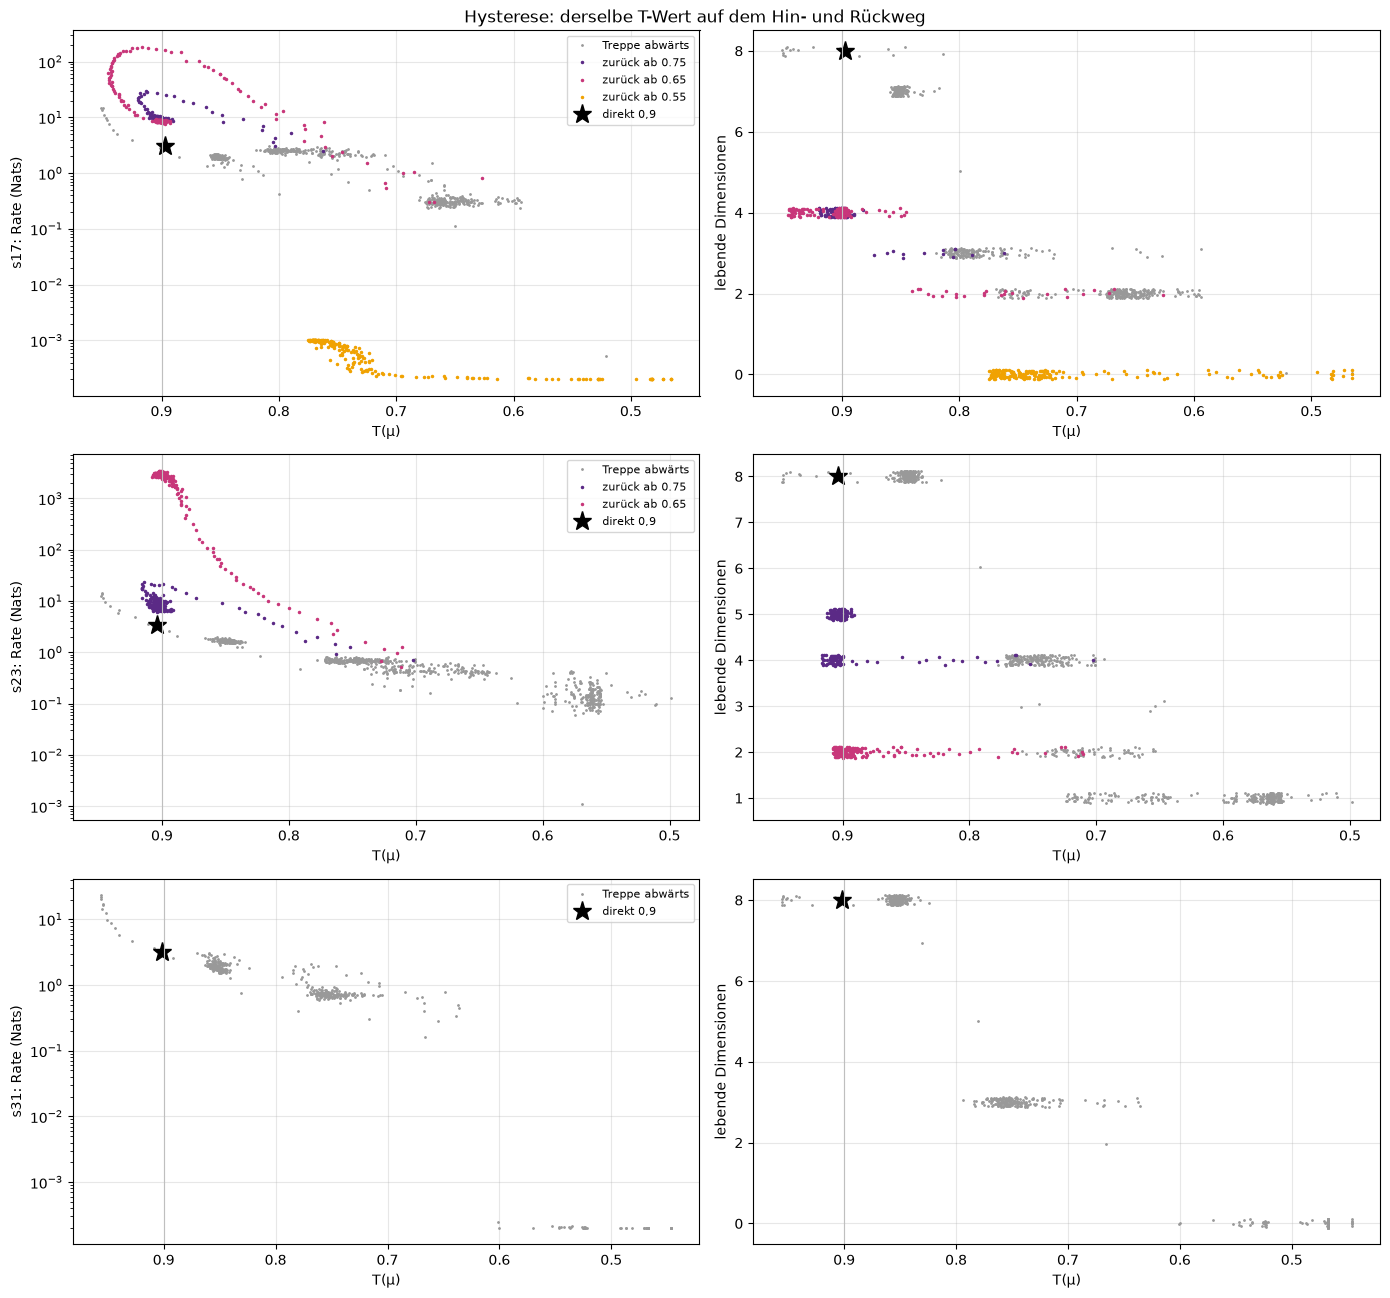

In [8]:
fig, axes = plt.subplots(len(stairs), 2, figsize=(14, 4.4 * len(stairs)), squeeze=False)
for row, (seed, log) in enumerate(stairs.items()):
    path = log.dropna(subset=["metric_value"]).loc[1100:]
    axes[row, 0].plot(path.metric_value, path.rate, ".", ms=2, color="0.6", label="Treppe abwärts")
    axes[row, 1].plot(path.metric_value, path.alive + np.random.default_rng(0).uniform(-.12, .12, len(path)), ".", ms=2,
                      color="0.6")
    for branch in BRANCHES:
        if (seed, branch) not in branches:
            continue
        back = branches[(seed, branch)].loc[level_end(branch) + 1:].dropna(subset=["metric_value"])
        axes[row, 0].plot(back.metric_value, back.rate, ".", ms=3, color=branch_colors[branch], label=f"zurück ab {branch}")
        axes[row, 1].plot(back.metric_value, back.alive + np.random.default_rng(1).uniform(-.12, .12, len(back)), ".",
                          ms=3, color=branch_colors[branch])
    if seed in direct:
        tail = direct[seed].iloc[-200:]
        axes[row, 0].plot(tail.metric_value.median(), tail.rate.median(), "k*", ms=14, label="direkt 0,9")
        axes[row, 1].plot(tail.metric_value.median(), tail.alive.median(), "k*", ms=14)
    axes[row, 0].set_yscale("log"); axes[row, 0].set_ylabel(f"s{seed}: Rate (Nats)")
    axes[row, 1].set_ylabel("lebende Dimensionen")
    for axis in axes[row]:
        axis.set_xlabel("T(μ)"); axis.axvline(RETURN_TARGET, color="0.75", lw=.8); axis.grid(alpha=.3)
        axis.invert_xaxis()
    axes[row, 0].legend(fontsize=8)
fig.suptitle("Hysterese: derselbe T-Wert auf dem Hin- und Rückweg")
fig.tight_layout()
fig.savefig(OUTPUT / "hysteresis.png", dpi=150)
plt.show()

In [9]:
cost_rows = []
for _, back in returns.iterrows():
    seed, branch = int(back.seed), back.Abzweig
    if seed not in direct:
        continue
    tail = direct[seed].iloc[-200:]
    teardown = speed[(speed.seed == seed) & (speed.Stufe == branch)]
    cost_rows.append(dict(
        seed=seed, Abzweig=branch, Comeback_T=bool(np.isfinite(back.T_stabil_nach)),
        Rate_zurueck=back.Rate_Ende, Rate_direkt=tail.rate.median(),
        Rate_Faktor=back.Rate_Ende / tail.rate.median(),
        Rate_pro_lebender_Dim_zurueck=back.Rate_Ende / max(back.lebend_am_Ende, 1),
        Rate_pro_lebender_Dim_direkt=tail.rate.median() / tail.alive.median(),
        bd_zurueck=back.bd_Ende, bd_direkt=tail.beta_over_d.median(),
        lebend_zurueck=back.lebend_am_Ende, lebend_direkt=int(tail.alive.median()),
        Abbau_erster_Tod=teardown.erster_Tod_nach.iloc[0] if len(teardown) else np.nan,
        Abbau_Endwert_haelt=teardown.Endwert_haelt_ab.iloc[0] if len(teardown) else np.nan,
        Aufbau_erste_Dim=back.erste_Dim_zurueck_nach, Aufbau_T_im_Band=back.T_im_Band_nach,
        Aufbau_T_stabil=back.T_stabil_nach))
cost = pd.DataFrame(cost_rows)
cost.to_csv(OUTPUT / "add_vs_remove_cost.csv", index=False)
display(cost.round(4))

,seed,Abzweig,Comeback_T,Rate_zurueck,Rate_direkt,Rate_Faktor,Rate_pro_lebender_Dim_zurueck,Rate_pro_lebender_Dim_direkt,bd_zurueck,bd_direkt,lebend_zurueck,lebend_direkt,Abbau_erster_Tod,Abbau_Endwert_haelt,Aufbau_erste_Dim,Aufbau_T_im_Band,Aufbau_T_stabil
0,17,0.75,True,9.1750,3.0486,3.0096,2.2937,0.3811,0.0003,0.0012,4.0,8,23.0,338.0,69.0,80.0,80.0
1,17,0.65,True,8.4657,3.0486,2.7769,2.1164,0.3811,0.0003,0.0012,4.0,8,53.0,61.0,131.0,185.0,440.0
2,17,0.55,False,0.0010,3.0486,0.0003,0.0010,0.3811,0.0000,0.0012,0.0,8,14.0,15.0,NaN,NaN,NaN
3,23,0.75,True,6.7112,3.3676,1.9929,1.3422,0.4210,0.0005,0.0011,5.0,8,16.0,160.0,394.0,90.0,90.0
4,23,0.65,True,3006.1750,3.3676,892.6700,1503.0875,0.4210,0.0000,0.0011,2.0,8,21.0,792.0,NaN,265.0,265.0


## 5. Befunde (gemessen; Stand 04.11.2026: Treppen s17/s23/s31, Abzweige s17 alle, s23 0,75 und 0,65)

Noch offen: Abzweig 0,55 von s23 und alle drei Abzweige von s31 (laufen). Beim erneuten Ausführen kommen sie dazu.

**1. Dimensionen gehen schnell und in Schüben verloren, immer während der β-Rampe des Controllers.**
- Der erste Tod kommt 14–76 Epochen nach dem Stufenwechsel (Tabelle §1), auf der Stufe 0,75 bei allen drei Seeds nach
  15–23 Epochen, und dann fallen 4–5 Dimensionen innerhalb von ≈ 10–15 Epochen.
- Bild 2: Die Tode fallen in den Anstieg auf die β-Spitze (β/d beim ersten Tod 2,6·10⁻³ – 7,3·10⁻³), nicht in die
  Haltephase danach. Der Controller schießt über und nimmt β erst zurück, wenn T schon unter dem Sollwert liegt.
- An der Grenze ε flackert der Zähler (s23 auf 0,75: 8-mal), weil einzelne Dimensionen knapp um 0,01 Nats liegen.

**2. Der vollständige Collapse kommt bei fast gleichem β, aber auf verschiedenen Stufen.**
- s31 bei Sollwert 0,65 (Epoche 3.123), s17 und s23 bei 0,55 (Epochen 4.115 und 4.841).
- β/d dabei 6,5·10⁻³ – 7,3·10⁻³ bei allen drei Seeds; das passt zur Collapse-Grenze β_total aus der 106er-Studie
  (4·10⁻³ – 8·10⁻³, `checklist.md`).
- s23 hält auf 0,55 eine letzte Dimension 740 Epochen lang (Rate ≈ 0,1 Nats), bis β/d langsam auf 6,5·10⁻³ steigt.
  Wenige Epochen nach dem Tod der letzten Dimension ist μ für alle Patienten 0 (`alle_mu_null_ab`).

**3. Zurück kommt T(μ), aber kaum Dimensionen; nach vollständigem Collapse kommt nichts zurück.**
- T(μ) ist 80–265 Epochen nach dem Rückschalten im Band 0,9 ± 0,01.
- Zurück kommen 0–2 Dimensionen, die erste nach 69–394 Epochen. Verloren waren 4–6.
- s23 ab 0,65: T im Band, aber keine Dimension zurück; der Controller fährt β auf 0, die Rate steigt auf ≈ 3.000 Nats.
  T(μ) allein meldet hier ein Comeback, das in Dimensionen keins ist.
- s17 ab vollständigem Collapse: in 1.000 Epochen bei β = 0 keine Dimension, T(μ) 0,77, Rate 10⁻³ Nats.

**4. Hinzufügen ist teurer als Wegnehmen**, in allen drei gemessenen Größen (Tabelle §4, Bild 4):

| | Wegnehmen (abwärts) | Hinzufügen (Rückweg auf 0,9) |
|---|---|---|
| Zeit | erster Tod nach 14–76 Epochen | erste Dimension nach 69–394 Epochen oder nie; T im Band nach 80–265 |
| Dimensionen | 4–5 in einem Schub (Stufe 0,75), bis zum Abzweig 4–6 | 0–2 |
| Rate bei T(μ) = 0,9 | direkter Lauf: 3,0–3,4 Nats (8 Dims) | 6,7–9,2 Nats (4–5 Dims), also 2,0–3,0×; s23 ab 0,65: ≈ 900× |
| Rate pro lebender Dimension | 0,38–0,42 Nats | 1,3–2,3 Nats (3–6×) |
| β/d bei T(μ) = 0,9 | 1,1–1,2·10⁻³ | 3–5·10⁻⁴ (2,3–4× weniger Druck nötig) |

- Lesart: Dieselbe Nachbarschaftstreue muss auf dem Rückweg von weniger Dimensionen getragen werden. Jede trägt mehr Rate,
  und der Controller muss β weit unter den direkten Wert senken. Bild 4 zeigt die Schleife: Die Rückwege laufen bei
  gleichem T eine bis drei Größenordnungen über der Treppe und landen über dem Stern des direkten Laufs.
- Die Rückwege schießen dabei über (Rate-Spitze 30–180 Nats bei s17, Bild 3), bevor sie sich setzen.

**Folgerung für den Annealer (hergeleitet aus 1 und 4):** Der Schaden entsteht in den ≈ 20 Epochen der β-Spitze und ist
danach nur teuer oder gar nicht rückgängig zu machen. Ein Schutz muss also die **Rampe** begrenzen (Schrittweite oder
Abbruch, sobald eine Dimension sich ε nähert), nicht erst den Haltewert. Ob das reicht, ist ungetestet.

**Grenzen.** 3 Seeds bei den Treppen, 2 bzw. 1 bei den Abzweigen; ein Controller (`SwitchingMaximinAnnealer`, Schritte
wie §14); TCGA, d = 8; Collapse-Kriterium ε = 0,01 Nats (Flackern an der Grenze).